## Problem 1: Visualise data in a static map (10 points)


Create a *static* **thematic map** using the skills you learnt during lesson 5. The map should <br>
contain more than one layer (from at least two different data sets). Pay attention to classification <br>
and visualisation (appropriate colour scheme choice, etc.). Write your code in this notebook, and <br>
store the resulting maps in `.png` format in the `NOTEBOOK_DIRECTORY / "docs"` folder.

### Topic of the map

- Use any of the data sets we have used during the course (travel time data, population grid), or <br>
  any other data set of your interest (for example, [open data sets from Statistics Finland](https://www.stat.fi/org/avoindata/index_en.html), <br>
  or the open geo-data from [the Helsinki Region Infoshare](https://hri.fi/en)). If you download <br>
  data sets, add, commit, and push them to the `DATA_DIRECTORY`. Be sure to include an attribution <br>
  to each data set in your output map!
- Feel free to start from and adapt examples from the course material! You can take one step further <br>
  and add additional analysis to, e.g., the shopping centre dominance or the population within vincinity <br>
  of certain addresses)

### Criteria

- The map has more than one data layer (for instance, the results of an analysis, and the road network <br>
  to illustrate a complex spatial pattern). If (and only if) you think it adds additional value, feel <br>
  free to add a base map (but a base map does not count as an own layer) (2 points)
- The map portrays the output of an analysis or a classification that adds value beyond just displaying <br>
  the raw data (3 points)
- The map follows good cartographic practices (appropriate map extent and zoom level, colour scheme, <br>
  legend and data sources, etc.) (5 points)

### Output

- Save the map(s) in `.png` format in the `NOTEBOOK_DIRECTORY / "docs"` folder, remember to add, commit, <br>
  and push them to the GitHub repository
- Remember to also add, commit, and push input data sets and code

---

This code creates a map of the occurrence of pedestrian road accidents during 2020-2024 nearby schools in Turku.

In [1]:
import pathlib 
NOTEBOOK_PATH = pathlib.Path().resolve()
DATA_DIRECTORY = NOTEBOOK_PATH / "data"
OUTPUT_DIRECTORY = NOTEBOOK_PATH / "docs"

In [2]:
# ADD YOUR OWN CODE HERE

In [3]:
import geopandas
# Statistics Finland WFS
WFS_BASE_URL = (
    "https://geo.stat.fi/geoserver/ows"
    "?service=wfs"
    "&version=2.0.0"
    "&request=GetFeature"
    "&srsName=EPSG:3067"
    "&typeName={layer:s}"
)
# Import layer of schools in Finland
schools = (
    geopandas.read_file(
        WFS_BASE_URL.format(layer="oppilaitokset")
    )
    .set_crs("EPSG: 3067")
)
schools.head()

ERROR 1: PROJ: proj_create_from_database: Open of /opt/conda/envs/cartogis2026/share/proj failed


,gml_id,id,oltyp_nimi,til_vuosi,tunn,onimi,olo,oltyp,euref_x,euref_y,geometry
0,oppilaitokset.1,1,Peruskoulut,2025,08888,Tusby träsk svenska skola,0,11,392861.0,6699246.0,POINT (392861 6699246)
1,oppilaitokset.2,2,Peruskoulut,2025,08871,Aapiskujan koulu,0,11,340457.0,7007582.0,POINT (340457 7007582)
2,oppilaitokset.3,3,Peruskoulut,2025,03117,Aarnivalkean koulu,0,11,378352.0,6673736.0,POINT (378352 6673736)
3,oppilaitokset.4,4,Peruskouluasteen erityiskoulut,2025,03874,Aavan koulu,0,12,372932.0,6756820.0,POINT (372932 6756820)
4,oppilaitokset.5,5,Peruskoulut,2025,03584,Ahjon koulu,0,11,397554.0,6697333.0,POINT (397554 6697333)


In [4]:
# Import layer of municipalities in Finland, so that we can crop the data to Turku
municipalities = (
    geopandas.read_file(
        WFS_BASE_URL.format(layer="kunta1000k_2016")
    )
    .set_crs("EPSG: 3067")
)
municipalities.head()

,gml_id,gid,vuosi,kunta,nimi,namn,name,geometry
0,kunta1000k_2016.1,1,2016.0,005,Alajärvi,Alajärvi,Alajärvi,"MULTIPOLYGON (((347302.684 6959056.438, 346754..."
1,kunta1000k_2016.2,2,2016.0,009,Alavieska,Alavieska,Alavieska,"MULTIPOLYGON (((370424.741 7104339.038, 370110..."
2,kunta1000k_2016.3,3,2016.0,010,Alavus,Alavus,Alavus,"MULTIPOLYGON (((319892.311 6920033.249, 317757..."
3,kunta1000k_2016.4,4,2016.0,016,Asikkala,Asikkala,Asikkala,"MULTIPOLYGON (((434407.88 6774122.311, 434003...."
4,kunta1000k_2016.5,5,2016.0,018,Askola,Askola,Askola,"MULTIPOLYGON (((423421.791 6704555.878, 422418..."


In [5]:
import pandas
# Import road accidents for 2020-2024 from Statistics Finland
accidents = pandas.concat([
    geopandas.read_file(
        WFS_BASE_URL.format(layer="tieliikenne:tieliikenne_2020")
    )
    .set_crs("EPSG: 3067"), 
    
    geopandas.read_file(
        WFS_BASE_URL.format(layer="tieliikenne:tieliikenne_2021")
    )
    .set_crs("EPSG: 3067"),
    
    geopandas.read_file(
        WFS_BASE_URL.format(layer="tieliikenne:tieliikenne_2022")
    )
    .set_crs("EPSG: 3067"),
    
    geopandas.read_file(
        WFS_BASE_URL.format(layer="tieliikenne:tieliikenne_2023")
    )
    .set_crs("EPSG: 3067"),
    
    geopandas.read_file(
        WFS_BASE_URL.format(layer="tieliikenne:tieliikenne_2024")
    )
    .set_crs("EPSG: 3067")
])
accidents = accidents[["gml_id", "onntyyppi", "x", "y", "geometry"]]
# 'onntype' column defines accident type. we are interested in pedestrian accidents so let's choose only: type 6 = pedestrian accident (at a crosswalk), 7 = pedestrian accident (elsewhere)
accidents = accidents.loc[accidents['onntyyppi'].isin(['6', '7'])]
accidents.head()

,gml_id,onntyyppi,x,y,geometry
0,tieliikenne_2020.1,7,391017.5427,6.674910e+06,POINT (391017.543 6674909.862)
2,tieliikenne_2020.3,6,384981.5744,6.671810e+06,POINT (384981.574 6671810.222)
3,tieliikenne_2020.4,6,386452.8138,6.672104e+06,POINT (386452.814 6672103.733)
5,tieliikenne_2020.6,6,384915.6212,6.678832e+06,POINT (384915.621 6678832.411)
8,tieliikenne_2020.9,6,382142.8117,6.670903e+06,POINT (382142.812 6670903.074)


In [6]:
# Crop schools and accidents to cover only Turku and save these layers to data folder
turku = municipalities[municipalities.name == "Turku"].copy()
turku

,gml_id,gid,vuosi,kunta,nimi,namn,name,geometry
280,kunta1000k_2016.280,280,2016.0,853,Turku,Åbo,Turku,"MULTIPOLYGON (((240357.887 6705903.86, 240360...."


In [7]:
turku_schools = schools[schools.within(turku.at[280,"geometry"])]
turku_accidents = accidents[accidents.within(turku.at[280,"geometry"])]

turku_schools.to_file(DATA_DIRECTORY/"turku_schools.gpkg")
turku_accidents.to_file(DATA_DIRECTORY/"turku_accidents.gpkg")

In [8]:
assert turku_schools.crs == turku_accidents.crs , "Input data sets’ CRS differs"

In [9]:
# Calculate how many pedestrian accidents have happened within 500 of each school
# First, create a 500m buffer for each school
turku_schools['buffer'] = turku_schools.geometry.buffer(distance=500)
# For joining based on the buffer, we need to set the buffer as the geometry
turku_schools_buffers = turku_schools.set_geometry("buffer")

# Next, join the accidents to the buffers based on spatial intersection
joined = geopandas.sjoin(
    turku_schools_buffers,
    turku_accidents,
    how="left",
    predicate="intersects"
)
accident_counts = joined.groupby(joined.index).agg(
    accident_count=("index_right", "count")
)
# Add accident counts to original schools GeoDataFrame
turku_schools["accident_count"] = accident_counts["accident_count"]
turku_schools.head()

,gml_id,id,oltyp_nimi,til_vuosi,tunn,onimi,olo,oltyp,euref_x,euref_y,geometry,buffer,accident_count
79,oppilaitokset.80,80,Peruskoulut,2025,08548,Aunelan koulu,0,11,236163.0,6711922.0,POINT (236163 6711922),"POLYGON ((236663 6711922, 236660.592 6711872.9...",1
111,oppilaitokset.112,112,Peruskoulut,2025,08808,Cygnaeus skola,0,11,239598.0,6711255.0,POINT (239598 6711255),"POLYGON ((240098 6711255, 240095.592 6711205.9...",13
211,oppilaitokset.212,212,Peruskoulut,2025,03760,Haarlan koulu,0,11,236611.0,6704848.0,POINT (236611 6704848),"POLYGON ((237111 6704848, 237108.592 6704798.9...",0
246,oppilaitokset.247,247,Peruskoulut,2025,08549,Hannunniitun koulu,0,11,242972.0,6711487.0,POINT (242972 6711487),"POLYGON ((243472 6711487, 243469.592 6711437.9...",0
303,oppilaitokset.304,304,Peruskoulut,2025,08550,Hepokullan koulu,0,11,238854.0,6713900.0,POINT (238854 6713900),"POLYGON ((239354 6713900, 239351.592 6713850.9...",0


In [10]:
# Import road network from Väylävirasto WFS for visualization of roads. Using bounding box of Turku because it's a heavy dataset
minx, miny, maxx, maxy = turku.total_bounds
VAYLA_WFS_BASE_URL = (
    "https://avoinapi.vaylapilvi.fi/vaylatiedot/digiroad/ows"
    "?service=wfs"
    "&version=2.0.0"
    "&request=GetFeature"
    "&srsName=EPSG:3067"
    "&typeName={layer:s}"
    "&outputFormat=application/json"
    f"&bbox={minx},{miny},{maxx},{maxy},EPSG:3067"
)

roads= (
    geopandas.read_file(
        VAYLA_WFS_BASE_URL.format(layer="digiroad:dr_nopeusrajoitus")
    )
    .set_crs("EPSG: 3067")
)
# Saving as a geopackage
roads.to_file(DATA_DIRECTORY / "turku_roads.gpkg")

In [11]:
# Cheking the schools_accident tables and inspecting what values are in the accident count
turku_schools.sort_values(by=["accident_count"]) 

,gml_id,id,oltyp_nimi,til_vuosi,tunn,onimi,olo,oltyp,euref_x,euref_y,geometry,buffer,accident_count
246,oppilaitokset.247,247,Peruskoulut,2025,08549,Hannunniitun koulu,0,11,242972.00000,6.711487e+06,POINT (242972 6711487),"POLYGON ((243472 6711487, 243469.592 6711437.9...",0
211,oppilaitokset.212,212,Peruskoulut,2025,03760,Haarlan koulu,0,11,236611.00000,6.704848e+06,POINT (236611 6704848),"POLYGON ((237111 6704848, 237108.592 6704798.9...",0
421,oppilaitokset.422,422,Peruskoulut,2025,08552,Ilpoisten koulu,0,11,240438.00000,6.707989e+06,POINT (240438 6707989),"POLYGON ((240938 6707989, 240935.592 6707939.9...",0
303,oppilaitokset.304,304,Peruskoulut,2025,08550,Hepokullan koulu,0,11,238854.00000,6.713900e+06,POINT (238854 6713900),"POLYGON ((239354 6713900, 239351.592 6713850.9...",0
521,oppilaitokset.522,522,Peruskoulut,2025,08553,Jäkärlän koulu,0,11,240994.00000,6.713973e+06,POINT (240994 6713973),"POLYGON ((241494 6713973, 241491.592 6713923.9...",0
941,oppilaitokset.941,941,Peruskoulut,2025,03364,Kuitinmäen koulu,0,11,243354.00000,6.708073e+06,POINT (243354 6708073),"POLYGON ((243854 6708073, 243851.592 6708023.9...",0
1106,oppilaitokset.1106,1106,Peruskoulut,2025,08559,Lausteen koulu,0,11,244708.00000,6.708507e+06,POINT (244708 6708507),"POLYGON ((245208 6708507, 245205.592 6708457.9...",0
1361,oppilaitokset.1362,1362,Peruskouluasteen erityiskoulut,2025,03688,Mylly-Antin koulu,0,12,240450.00000,6.715639e+06,POINT (240450 6715639),"POLYGON ((240950 6715639, 240947.592 6715589.9...",0
1551,oppilaitokset.1552,1552,Peruskoulut,2025,03797,Paattisten koulu,0,11,247069.00000,6.726209e+06,POINT (247069 6726209),"POLYGON ((247569 6726209, 247566.592 6726159.9...",0
1926,oppilaitokset.1927,1927,Peruskouluasteen erityiskoulut,2025,03314,Satulavuoren koulu,0,12,243070.00000,6.708913e+06,POINT (243070 6708913),"POLYGON ((243570 6708913, 243567.592 6708863.9...",0


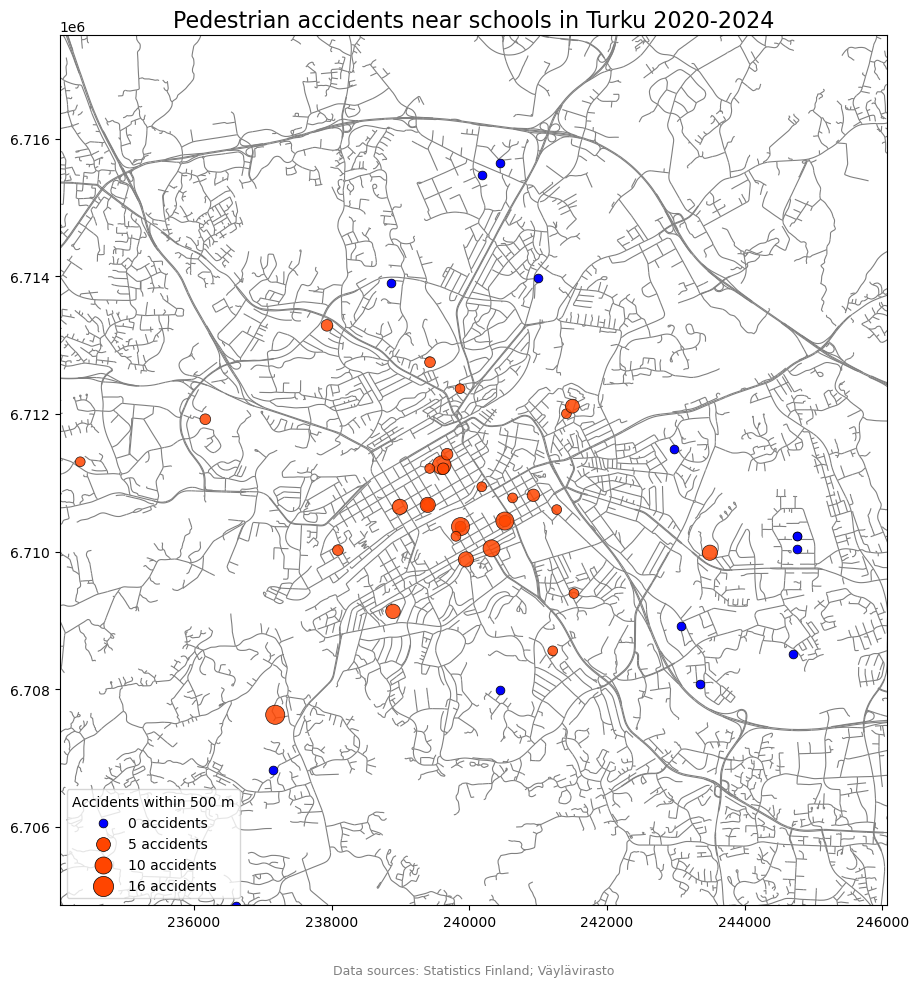

<Figure size 640x480 with 0 Axes>

In [12]:
import matplotlib.pyplot as plt
import contextily

ax = roads.plot(
    figsize=(12, 10),
    color = "grey",
    linewidth=0.8, 
    zorder=1
)
# Plot schools, with marker size based on accident count and schools with no accidents as blue
# Separate schools based on accident count
schools_zero = turku_schools[
    turku_schools["accident_count"] == 0
]
schools_accidents = turku_schools[
    turku_schools["accident_count"] > 0
]
# Plot schools with 0 accidents
schools_zero.plot(
    ax=ax,
    color="blue",
    edgecolor="black",
    linewidth=0.5,
    markersize=40,
    zorder=2
)
# Plot schools with 1 or more accidents
schools_accidents.plot(
    ax=ax,
    color="orangered",
    edgecolor="black",
    linewidth=0.5,
    markersize=50 + turku_schools["accident_count"] * 10,
    alpha=0.85,
    zorder=3
    
)
# Create legend that matced marker sizes and colors
for count in [0, 5, 10, 16]:
    ax.scatter(
        [],
        [],
        s=40 if count == 0 else 50 + count * 10,
        color="blue" if count == 0 else "orangered",
        edgecolor="black",
        linewidth=0.5,
        label=f"{count} accidents"
    )

ax.legend(
    title="Accidents within 500 m",
    loc="lower left"
)
# Set map extent
minx, miny, maxx, maxy = 234046., 6704860.,  246069., 6717500.
ax.set_xlim(minx, maxx)
ax.set_ylim(miny, maxy)


ax.set_title(
    "Pedestrian accidents near schools in Turku 2020-2024",
    fontsize=16
)
# Add data source attribution
ax.figure.text(
    0.5, 0.02,
    "Data sources: Statistics Finland; Väylävirasto",
    ha="center",
    fontsize=9,
    color="gray"

)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()
plt.savefig(
    OUTPUT_DIRECTORY / "accidents_near_schools.png",
    dpi=300,
    bbox_inches="tight"
)
ax.set_axis_off()

plt.tight_layout()
plt.show()


In [23]:
# dropping the buffer column so that I can save the schools to a geopackage
#turku_schools_accidents = turku_schools.drop(["buffer"])
turku_schools_accidents.to_file(DATA_DIRECTORY / "turku_schools_accidents.gpkg")